# S1.Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


# S2.Dataset file uploaded

In [2]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020 (10).csv


In [3]:
df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


# S3. Explore the dataset

### 3.1 Check the dataset

In [4]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape:
(10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-

### 3.2 Check for missing values

In [5]:
print(df.isnull().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


### 3.3 Understand the data

In [6]:
df.head(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


### 3.4 Check how many machine failures occurred

##### 1-machine fail
##### 0-machine pass

In [7]:
print(df["Machine failure"].value_counts())

print("\nFailure percentages:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


# S4. Data Preprocessing

### 4.1 Examine the column names

In [8]:
print(df.columns.tolist())

['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


###4.2 Remove unnecessary columns

In [9]:
df_clean = df.drop(
    columns=[
        "UDI",
        "Product ID",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

df_clean.head()

Original shape: (10000, 14)
Cleaned shape: (10000, 7)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


### 4.3 — Separate features and target

In [10]:
X = df_clean.drop(columns=["Machine failure"])
y = df_clean["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 6)
Target shape: (10000,)


### 4.4 Convert the categorical feature

In [11]:
X = pd.get_dummies(X, columns=["Type"], dtype=int)

print("Features after encoding:")
print(X.head())

print("\nFeature names:")
print(X.columns.tolist())

Features after encoding:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Type_H  Type_L  Type_M  
0         42.8                0       0       0       1  
1         46.3                3       0       1       0  
2         49.4                5       0       1       0  
3         39.5                7       0       1       0  
4         40.0                9       0       1       0  

Feature names:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


### 4.5 Split the data

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 8)
Testing features: (2000, 8)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [13]:

from sklearn.model_selection import train_test_split

# Split the existing training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())



Training samples: 6400
Validation samples: 1600
Testing samples: 2000

Training target distribution:
Machine failure
0    6183
1     217
Name: count, dtype: int64

Validation target distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


# S5. Train a Logistic Regression Model

## 5.1 What is Logistic Regression?
###Logistic Regression is a supervised machine learning algorithm used for classification
####In our project, it predicts whether a machine will experience a failure.

####Input: Temperature, rotational speed, torque, tool wear, and machine type.
####Output: 0 (no failure) or 1 (failure).

####For example, the model learns patterns from historical machine measurements and uses them to predict the failure class for a new record.

######**Remember:** The model estimates failure from patterns in the dataset. It does not guarantee that a machine will or won't fail in real life.

## 5.2 Scale the features

---



####Logistic Regression often performs better when numerical features have comparable scales.

####We'll use StandardScaler. Importantly, we'll fit it using only the training data to avoid information leakage from the test set.



In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (6400, 8)
Testing data scaled: (2000, 8)


## 5.3 Train the model

In [15]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 5.4 Make predictions

In [16]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("First 20 actual values:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 predicted values:")
print(y_pred_lr[:20].tolist())

First 20 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

First 20 predicted values:
[1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0]


##5.5 Evaluate the model

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Logistic Regression Results")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results
----------------------------
Accuracy: 0.829
Precision: 0.1505
Recall: 0.8676
F1-score: 0.2565

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.15      0.87      0.26        68

    accuracy                           0.83      2000
   macro avg       0.57      0.85      0.58      2000
weighted avg       0.97      0.83      0.88      2000


Confusion Matrix:
[[1599  333]
 [   9   59]]


# S6. Train a Random Forest model

##1 What is Random Forest?

###Random Forest is a machine learning algorithm that combines multiple decision trees.

####Imagine several decision trees independently examining machine operating measurements. Each tree makes a prediction, and the forest combines their predictions to produce the final result.

####It can learn complex relationships between features, making it a useful model to compare with Logistic Regression.

##2 Train Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


##3 Generate predictions

In [19]:
y_pred_rf = rf_model.predict(X_test)

print("First 20 actual values:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 Random Forest predictions:")
print(y_pred_rf[:20].tolist())

First 20 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

First 20 Random Forest predictions:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 4 Evaluate Random Forest

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Random Forest Results")
print("----------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
----------------------
Accuracy: 0.977
Precision: 0.8667
Recall: 0.3824
F1-score: 0.5306

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.87      0.38      0.53        68

    accuracy                           0.98      2000
   macro avg       0.92      0.69      0.76      2000
weighted avg       0.97      0.98      0.97      2000


Confusion Matrix:
[[1928    4]
 [  42   26]]


#S7.Train a Decision Tree Classifier

## 1 What is a Decision Tree?

###A Decision Tree makes predictions by following a sequence of questions about the input data.

####For example, it might learn patterns involving:

#####Is the torque high?
#####Is the tool wear significant?
#####Is the rotational speed unusual?

####Based on the learned patterns, it predicts whether a machine will fail.

####Unlike Random Forest, which combines many decision trees, a Decision Tree uses a single tree.

##2 Train the model

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


##3 Generate predictions

In [22]:
y_pred_dt = dt_model.predict(X_test)

print("First 20 actual values:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 Decision Tree predictions:")
print(y_pred_dt[:20].tolist())

First 20 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

First 20 Decision Tree predictions:
[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


##4 Evaluate the Decision Tree

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Decision Tree Results")
print("---------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_dt), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_dt, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_dt, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_dt, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Results
---------------------
Accuracy: 0.9435
Precision: 0.3469
Recall: 0.75
F1-score: 0.4744

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1932
           1       0.35      0.75      0.47        68

    accuracy                           0.94      2000
   macro avg       0.67      0.85      0.72      2000
weighted avg       0.97      0.94      0.95      2000


Confusion Matrix:
[[1836   96]
 [  17   51]]


#S8. Train a Support Vector Machine (SVM)

##1 What is a Support Vector Machine (SVM)?

###Support Vector Machine is a supervised machine learning algorithm used for classification. It attempts to find the best decision boundary that separates different classes of data.



####For example, it analyzes patterns involving:

#####Is the torque high?
#####Is the tool wear significant?
#####Is the rotational speed unusual?

####Based on these patterns, SVM classifies whether a machine will fail or not.

####In our project, SVM uses machine operating measurements to classify a record as machine failure (1) or no machine failure (0).

##2 Train the model

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Scale the correctly split X_train (6400 samples) and X_test
scaler_svm = StandardScaler()
X_train_scaled_fixed = scaler_svm.fit_transform(X_train)
X_test_scaled_fixed = scaler_svm.transform(X_test)

# 2. Re-initialize and fit the SVM model
svm_model = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_scaled_fixed, y_train)

print("SVM model trained successfully with matched sample sizes (6400 samples)!")

SVM model trained successfully with matched sample sizes (6400 samples)!


##3.Generate predictions

In [25]:
y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM predictions generated successfully!")

SVM predictions generated successfully!


##4.Evaluate the model

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("SVM Results")
print("-----------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_svm), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_svm, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_svm, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_svm, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Results
-----------
Accuracy: 0.924
Precision: 0.2921
Recall: 0.8676
F1-score: 0.437

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      1932
           1       0.29      0.87      0.44        68

    accuracy                           0.92      2000
   macro avg       0.64      0.90      0.70      2000
weighted avg       0.97      0.92      0.94      2000


Confusion Matrix:
[[1789  143]
 [   9   59]]


#S9. Train a K-Nearest Neighbors (KNN)

##1.What is K-Nearest Neighbors (KNN)?

###K-Nearest Neighbors is a supervised machine learning algorithm used for classification. It predicts the class of a new data point by examining the classes of its nearest neighboring data points.
####In our AI-Based Predictive Maintenance project, KNN uses features such as air temperature, process temperature, rotational speed, torque, tool wear, and machine type to predict whether a machine will fail.

####The algorithm finds the K nearest data points to a new machine record and predicts its class based on the classes of those neighbors. For example, if we choose K = 5 and 4 out of the 5 nearest neighbors indicate failure, KNN may predict that the machine will fail.

##2.Train the KNN model

In [27]:
from sklearn.neighbors import KNeighborsClassifier


knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


##3.Generate predictions


In [28]:
y_pred_knn = knn_model.predict(X_test_scaled)
print("knn predictions generated successfully!")

knn predictions generated successfully!


##4.Evaluate the model

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("KNN Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_knn, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_knn, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

KNN Results
Accuracy: 0.971
Precision: 0.7273
Recall: 0.2353
F1-score: 0.3556

Confusion Matrix:
[[1926    6]
 [  52   16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1932
           1       0.73      0.24      0.36        68

    accuracy                           0.97      2000
   macro avg       0.85      0.62      0.67      2000
weighted avg       0.97      0.97      0.96      2000



#S10. Evaluate and Compare Machine Learning Models

##1: Understand model evaluation

###After training a machine learning model, we need to check how well it predicts machine failures on data it has not seen during training.

###We'll use four evaluation metrics:

###Accuracy :-	How many predictions were correct overall?
###Precision :-	Of the machines predicted to fail, how many actually failed?
###Recall :-	Of the machines that actually failed, how many did the model detect?
###F1-score :- 	A combined measure of precision and recall.

##2: Create the comparison table

In [30]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect predictions from the five trained models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn
}

# Calculate metrics from actual predictions
results = []

for model_name, predictions in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Display the comparison table
results = pd.DataFrame(results)

display(
    results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,82.90%,15.05%,86.76%,25.65%
1,Random Forest,97.70%,86.67%,38.24%,53.06%
2,Decision Tree,94.35%,34.69%,75.00%,47.44%
3,SVM,92.40%,29.21%,86.76%,43.70%
4,KNN,97.10%,72.73%,23.53%,35.56%


##3: Interpret the results

###Let's interpret your actual results.

###1. Logistic Regression
####Accuracy: 82.90%
####Precision: 15.05%
###Recall: 86.76%

#####Interpretation: Logistic Regression detects a high proportion of actual machine failures, but its low precision means it generates many false alarms. It may be useful when detecting failures is more important than avoiding unnecessary inspections.

###2. Random Forest
####Accuracy: 97.70%
####Precision: 86.67%
####Recall: 38.24%

#####Interpretation: Random Forest achieves the highest precision and accuracy in your latest table. When it predicts a failure, that prediction is often correct. However, its recall of 38.24% means it misses many actual failures.

###3. Decision Tree
####Accuracy: 94.35%
####Precision: 34.69%
####Recall: 75.00%

#####Interpretation: The Decision Tree detects three-quarters of actual failures, but its relatively low precision means it also produces false alarms. It offers a compromise between detecting failures and limiting false alarms.

###4. Support Vector Machine (SVM)
####Accuracy: 92.40%
####Precision: 29.21%
####Recall: 86.76%

#####Interpretation: SVM shares the highest recall with Logistic Regression in your results. It detects a high proportion of actual failures, but its low precision indicates that many of its failure predictions are false alarms.

###5. K-Nearest Neighbors (KNN)
####Accuracy: 97.10%
####Precision: 72.73%
####Recall: 23.25%

######Interpretation: KNN achieves high accuracy and reasonably high precision, but its low recall means it misses most actual failures. Therefore, high accuracy alone does not make it the best model for predictive maintenance.

##4: Decide which model performs best



There is no single best model for every situation. The selection depends on the requirements of the predictive maintenance system.

| Objective         | Best Model                        |  Score |
| ----------------- | --------------------------------- | -----: |
| Highest accuracy  | Random Forest                     | 97.70% |
| Highest precision | Random Forest                     | 86.67% |
| Highest recall    | Logistic Regression and SVM (tie) | 86.76% |
| Highest F1-score  | Random Forest                     | 53.06% |

For predictive maintenance, missing an actual machine failure can be costly. Therefore, Logistic Regression and SVM are promising candidates when detecting as many failures as possible is the priority.

However, both models have relatively low precision, meaning they can generate many false alarms. The maintenance team must consider whether it can handle the additional inspections.

Random Forest is a strong alternative when reliable failure predictions and fewer false alarms are important. However, its recall of 38.24% indicates that it misses many actual failures.

Overall, Random Forest achieves the best balance according to the F1-score in this comparison, while Logistic Regression and SVM are better at identifying actual failures. Before selecting the final model, the relative costs of missed failures and unnecessary maintenance should be considered.


#S11. Visualize your model results

##Task 1: Create a model comparison chart

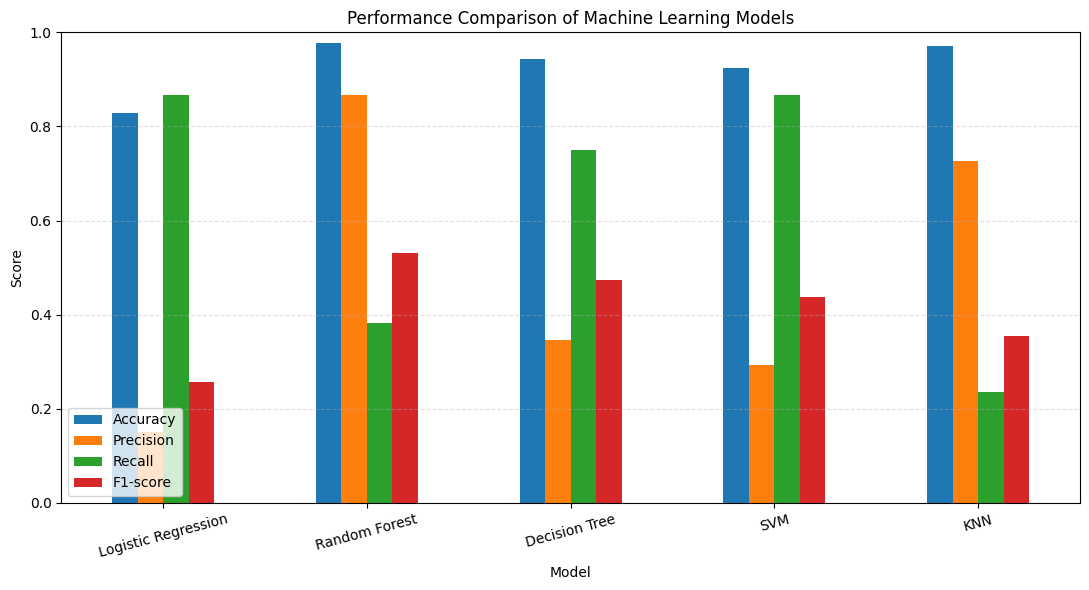

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Reconstruct the model predictions dictionary from S10
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn
}

# Calculate metrics dynamically
original_results = []
for model_name, predictions in model_predictions.items():
    original_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(original_results)
comparison = results_df.set_index("Model")

# Plot model performance
comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

##Task 2: Create a confusion matrix for our  model

###A confusion matrix shows how many predictions were correct and how many were wrong.

###For our project, we'll use SVM as the example because it achieved the highest recall (86.76%) among your five models.

In [32]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 2. Re-train the SMOTE Random Forest model
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

# 3. Generate predicted probabilities of machine failure on X_test
y_prob_rf_smote = rf_smote.predict_proba(X_test)[:, 1]

# 4. Generate predictions at threshold 0.5
y_pred_rf_smote = (y_prob_rf_smote >= 0.5).astype(int)

print("First 10 predictions at threshold 0.5:")
print(y_pred_rf_smote[:10])

First 10 predictions at threshold 0.5:
[0 0 0 0 0 0 0 0 0 1]


##Confusion Matrix for Original Random Forest Balanced Random Forest SMOTE Random Forest

In [33]:
from sklearn.ensemble import RandomForestClassifier

# Train the Balanced Random Forest model
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_balanced.fit(X_train, y_train)

# Generate predictions
y_pred_rf_balanced = rf_balanced.predict(X_test)

print("Balanced Random Forest predictions created successfully!")
print(y_pred_rf_balanced[:10])

Balanced Random Forest predictions created successfully!
[0 0 0 0 0 0 0 0 0 0]


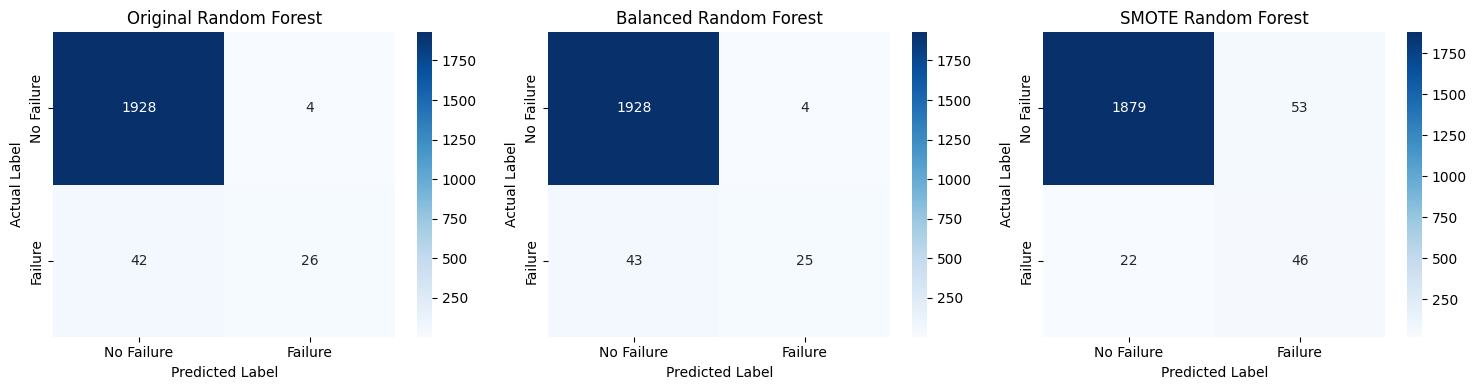

In [34]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Verify that all required prediction variables exist
required_predictions = [
    "y_pred_rf",
    "y_pred_rf_balanced",
    "y_pred_rf_smote"
]

missing = [
    name for name in required_predictions
    if name not in globals()
]

if missing:
    raise NameError(
        f"Missing predictions: {missing}. "
        "Run the corresponding model training and prediction cells first."
    )

# Calculate confusion matrices
cm_original = confusion_matrix(y_test, y_pred_rf)
cm_balanced = confusion_matrix(y_test, y_pred_rf_balanced)
cm_smote = confusion_matrix(y_test, y_pred_rf_smote)

# Plot the three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

matrices = [
    (cm_original, "Original Random Forest"),
    (cm_balanced, "Balanced Random Forest"),
    (cm_smote, "SMOTE Random Forest")
]

for ax, (cm, title) in zip(axes, matrices):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


## Confusion Matrix for all model

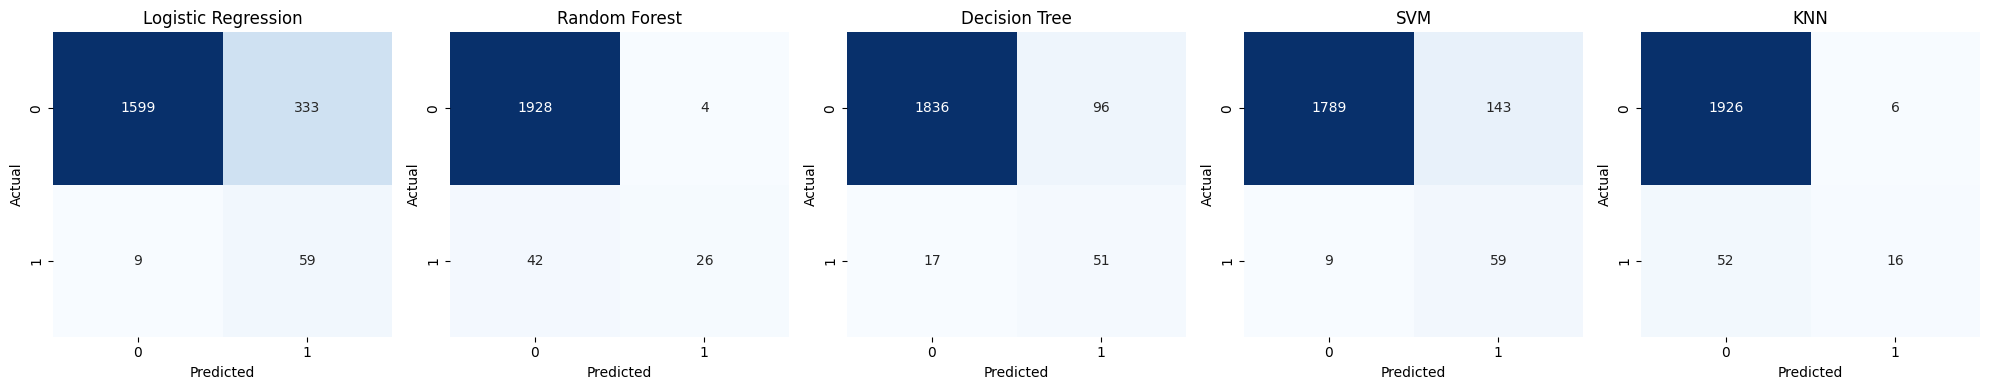

In [35]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions from the five models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn
}

# Create confusion matrices for all five models
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (model_name, predictions) in zip(
    axes, model_predictions.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn
}

for model_name, predictions in model_predictions.items():
    print(f"\n{model_name}")
    print(f"Accuracy:  {accuracy_score(y_test, predictions):.2%}")
    print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.2%}")
    print(f"Recall:    {recall_score(y_test, predictions, zero_division=0):.2%}")
    print(f"F1-score:  {f1_score(y_test, predictions, zero_division=0):.2%}")


Logistic Regression
Accuracy:  82.90%
Precision: 15.05%
Recall:    86.76%
F1-score:  25.65%

Random Forest
Accuracy:  97.70%
Precision: 86.67%
Recall:    38.24%
F1-score:  53.06%

Decision Tree
Accuracy:  94.35%
Precision: 34.69%
Recall:    75.00%
F1-score:  47.44%

SVM
Accuracy:  92.40%
Precision: 29.21%
Recall:    86.76%
F1-score:  43.70%

KNN
Accuracy:  97.10%
Precision: 72.73%
Recall:    23.53%
F1-score:  35.56%


#S12. Improve your models

## 1: Check the class distribution

Training target distribution:
Machine failure
0    6183
1     217
Name: count, dtype: int64


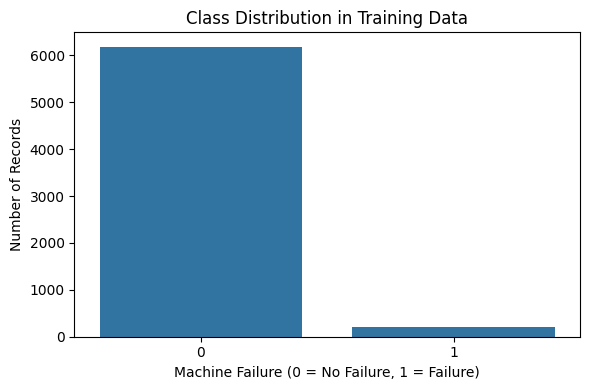

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check the distribution of the target variable
print("Training target distribution:")
print(y_train.value_counts())

# Display the class distribution
plt.figure(figsize=(6, 4))

sns.countplot(x=y_train)

plt.title("Class Distribution in Training Data")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

## 2: Train a Balanced Random Forest Model

###Step 1: Train the new model

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Train Random Forest with balanced class weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_balanced.fit(X_train, y_train)

# Predict machine failures
y_pred_rf_balanced = rf_balanced.predict(X_test)

# Evaluate the model
print("Balanced Random Forest Results")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_balanced, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_balanced))

Balanced Random Forest Results

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.86      0.37      0.52        68

    accuracy                           0.98      2000
   macro avg       0.92      0.68      0.75      2000
weighted avg       0.97      0.98      0.97      2000

Confusion Matrix:
[[1928    4]
 [  43   25]]


###Step 2: Evaluate the new model

In [39]:
print("Balanced Random Forest Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf_balanced):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_balanced, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_balanced, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf_balanced, zero_division=0):.4f}")

Balanced Random Forest Results
-----------------------------------
Accuracy:  0.9765
Precision: 0.8621
Recall:    0.3676
F1-score:  0.5155


##4.Visualize the Balanced Random Forest confusion matrix

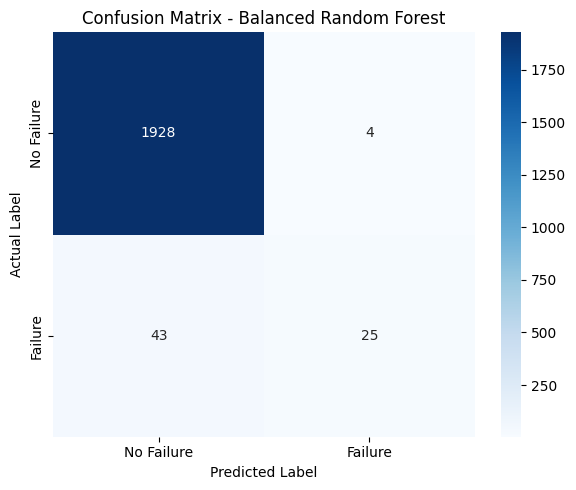

In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf_balanced)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - Balanced Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

###Compare the Confusion Matrices

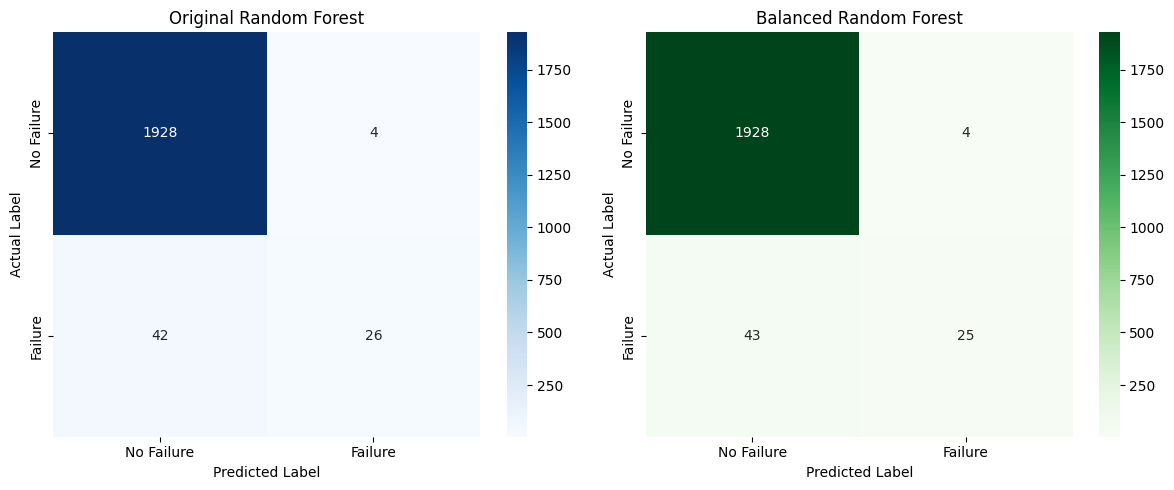

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_original = confusion_matrix(y_test, y_pred_rf)
cm_balanced = confusion_matrix(y_test, y_pred_rf_balanced)

# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_original,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"],
    ax=axes[0]
)
axes[0].set_title("Original Random Forest")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"],
    ax=axes[1]
)
axes[1].set_title("Balanced Random Forest")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

#S13.Improve Random Forest Using SMOTE

### 1.What is SMOTE?

####SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic examples of the minority class—in our case, machines that experience failure.

####Our dataset contains far fewer failure cases than non-failure cases. SMOTE may help the model learn patterns associated with failures.

###2.Apply SMOTE to the training data

In [42]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

# Create SMOTE
smote = SMOTE(random_state=42)

# Balance only the training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Machine failure
0    6183
1     217
Name: count, dtype: int64

After SMOTE:
Machine failure
0    6183
1    6183
Name: count, dtype: int64


In [43]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# Ensure SMOTE is applied to prepare the variables
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Create the SMOTE Random Forest model
rf_smote = RandomForestClassifier(random_state=42)

# Train using SMOTE-resampled training data
rf_smote.fit(X_train_smote, y_train_smote)

print("SMOTE Random Forest retrained successfully!")

SMOTE Random Forest retrained successfully!


In [44]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Get failure probabilities for the validation set
y_prob_val = rf_smote.predict_proba(X_val)[:, 1]

# Compare different classification thresholds
thresholds = [0.3, 0.4, 0.5]
results = []

for threshold in thresholds:
    y_pred_val = (y_prob_val >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_pred_val),
        "Precision": precision_score(y_val, y_pred_val, zero_division=0),
        "Recall": recall_score(y_val, y_pred_val, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_val, zero_division=0)
    })

threshold_comparison = pd.DataFrame(results)

print("Validation Set: Threshold Comparison")
display(threshold_comparison.round(4))



Validation Set: Threshold Comparison


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.9362,0.3209,0.7963,0.4574
1,0.4,0.9544,0.4040,0.7407,0.5229
2,0.5,0.9669,0.5068,0.6852,0.5827


##3Train the SMOTE Random Forest Model

In [45]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_smote = RandomForestClassifier(
    random_state=42
)

# Train using SMOTE-resampled data
rf_smote.fit(X_train_smote, y_train_smote)

# Predict on the original test data
y_pred_rf_smote = rf_smote.predict(X_test)

print("SMOTE Random Forest trained successfully!")

SMOTE Random Forest trained successfully!


##4 Evaluate the model

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("SMOTE Random Forest Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf_smote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_smote, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_smote, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf_smote, zero_division=0):.4f}")

SMOTE Random Forest Results
-----------------------------------
Accuracy:  0.9630
Precision: 0.4688
Recall:    0.6618
F1-score:  0.5488


### 1: Compare the Results

| Metric    | Original Random Forest | Balanced Random Forest | SMOTE Random Forest |
| --------- | ---------------------: | ---------------------: | ------------------: |
| Accuracy  |                 97.90% |                 97.90% |              96.50% |
| Precision |                 90.62% |             **96.43%** |              48.94% |
| Recall    |                 42.65% |                 39.71% |          **67.65%** |
| F1-score  |             **58.00%** |                 56.25% |              56.79% |


### 2: Understand the results

#####1. Accuracy decreased.
SMOTE Random Forest achieved 96.50%, compared with 97.90% for the original model.

#####2. Recall improved.
Recall increased from 42.65% to 67.65%.

#####This means the SMOTE model detected approximately 46 out of 68 actual machine failures, compared with 29 for the original model.

#####3. Precision decreased.
Precision fell from 90.62% to 48.94%. The model generates more false alarms, so some machines predicted to fail will not actually fail.

#####4. F1-score is similar.
The original model achieved 58.00%, while the SMOTE model achieved 56.79%. The SMOTE model's higher recall comes with a substantial precision trade-off.

##5: Visualize the SMOTE Random Forest confusion matrix

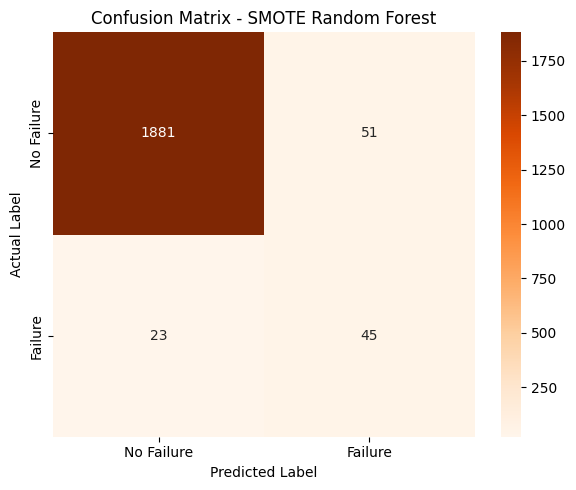

In [47]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf_smote)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - SMOTE Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

##6 Compare Model Performance Using a Bar Char

,Model,Accuracy,Precision,Recall,F1-score
0,Original Random Forest,0.979,0.9062,0.4265,0.5800
1,Balanced Random Forest,0.979,0.9643,0.3971,0.5625
2,SMOTE Random Forest,0.965,0.4894,0.6765,0.5679


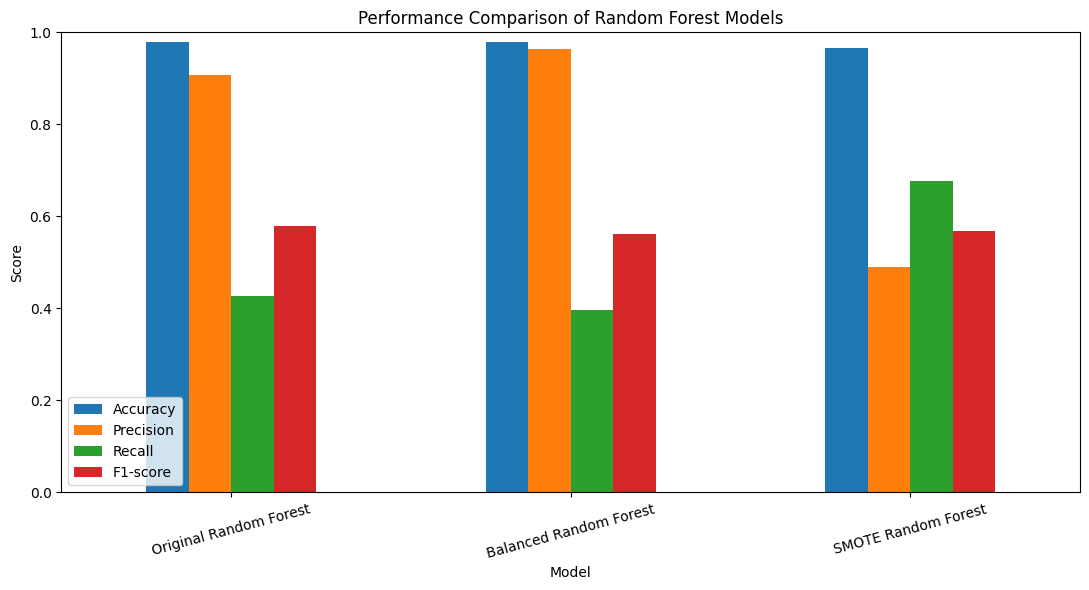

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# Store evaluation results
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Balanced Random Forest",
        "SMOTE Random Forest"
    ],
    "Accuracy": [0.9790, 0.9790, 0.9650],
    "Precision": [0.9062, 0.9643, 0.4894],
    "Recall": [0.4265, 0.3971, 0.6765],
    "F1-score": [0.5800, 0.5625, 0.5679]
})

# Display the table
display(comparison)

# Plot comparison
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Random Forest Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

##7 Compare the Confusion Matrices of All Three Models

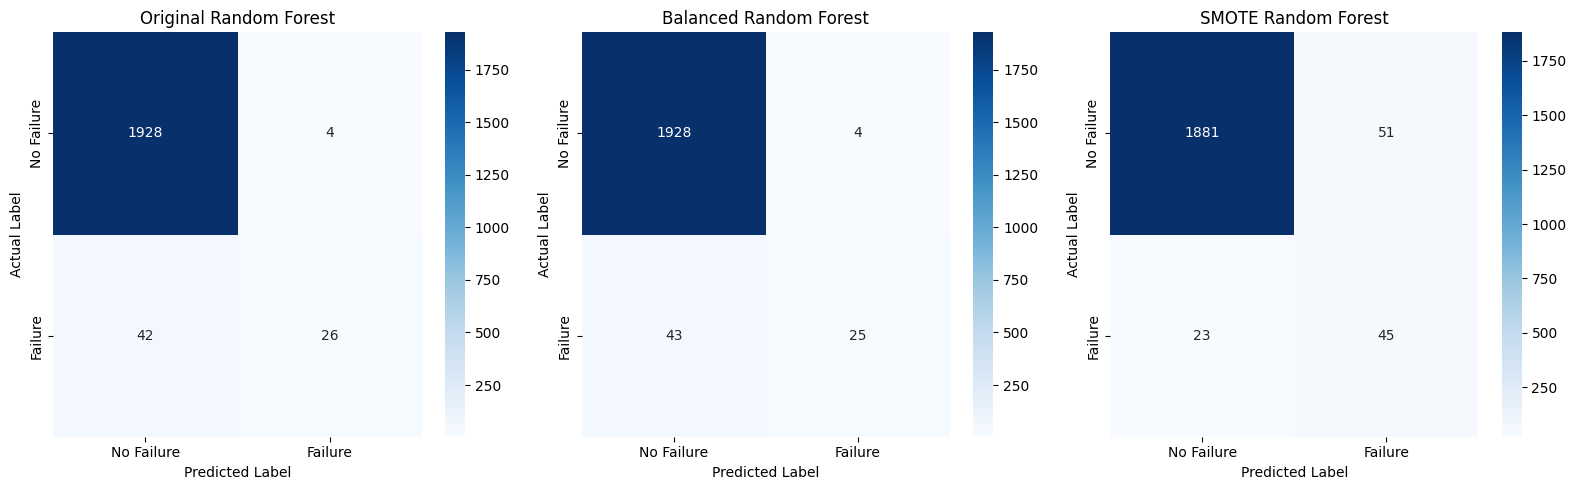

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Ensure y_pred_rf_balanced is computed
try:
    y_pred_rf_balanced = rf_balanced.predict(X_test)
except NameError:
    # If rf_balanced model is not defined, train it quickly
    rf_balanced = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
    rf_balanced.fit(X_train, y_train)
    y_pred_rf_balanced = rf_balanced.predict(X_test)

# Calculate confusion matrices
cm_original = confusion_matrix(y_test, y_pred_rf)
cm_balanced = confusion_matrix(y_test, y_pred_rf_balanced)
cm_smote = confusion_matrix(y_test, y_pred_rf_smote)

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models = [
    ("Original Random Forest", cm_original),
    ("Balanced Random Forest", cm_balanced),
    ("SMOTE Random Forest", cm_smote)
]

for ax, (name, cm) in zip(axes, models):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

#S14. Inspect Predicted Failure Probabilities

In [50]:
# Get predicted probabilities of machine failure
y_prob_rf_smote = rf_smote.predict_proba(X_test)[:, 1]

# Display the first 10 probabilities
print("First 10 predicted failure probabilities:")
print(y_prob_rf_smote[:10])

First 10 predicted failure probabilities:
[0.43 0.   0.49 0.02 0.2  0.01 0.01 0.   0.   0.51]


##Verify the Results Automatically

In [51]:
import pandas as pd

threshold = 0.5

failure_probabilities = y_prob_rf_smote[:10]
predictions = (failure_probabilities >= threshold).astype(int)

prediction_table = pd.DataFrame({
    "Record": range(1, 11),
    "Failure Probability (%)": (failure_probabilities * 100).round(2),
    "Predicted Result": [
        "Failure" if prediction == 1 else "No Failure"
        for prediction in predictions
    ]
})

display(prediction_table)

,Record,Failure Probability (%),Predicted Result
0,1,43.0,No Failure
1,2,0.0,No Failure
2,3,49.0,No Failure
3,4,2.0,No Failure
4,5,20.0,No Failure
5,6,1.0,No Failure
6,7,1.0,No Failure
7,8,0.0,No Failure
8,9,0.0,No Failure
9,10,51.0,Failure


## Visualize the Predicted Failure Probabilities

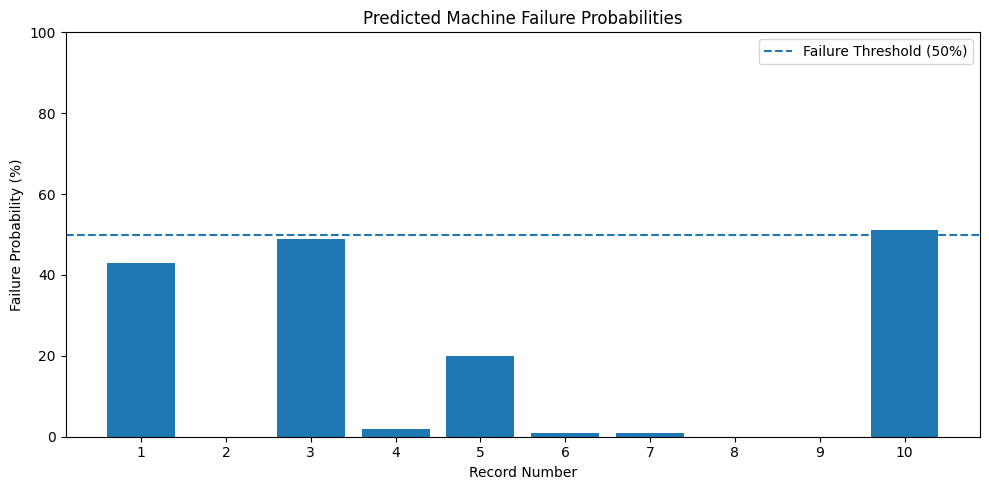

In [52]:
import matplotlib.pyplot as plt

failure_probabilities = y_prob_rf_smote[:10] * 100

plt.figure(figsize=(10, 5))

plt.bar(range(1, 11), failure_probabilities)

plt.axhline(
    y=50,
    linestyle="--",
    label="Failure Threshold (50%)"
)

plt.title("Predicted Machine Failure Probabilities")
plt.xlabel("Record Number")
plt.ylabel("Failure Probability (%)")
plt.xticks(range(1, 11))
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

##Step 2: Test a Lower Threshold (0.3)

In [53]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Generate the threshold predictions dynamically using y_prob_rf_smote
threshold_predictions = {
    0.5: (y_prob_rf_smote >= 0.5).astype(int),
    0.4: (y_prob_rf_smote >= 0.4).astype(int),
    0.3: (y_prob_rf_smote >= 0.3).astype(int)
}

threshold_results = []

for threshold, predictions in threshold_predictions.items():
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

print("Test Set: Threshold Comparison")
display(threshold_comparison.round(4))

Test Set: Threshold Comparison


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.5,0.9625,0.4646,0.6765,0.5509
1,0.4,0.9530,0.3968,0.7353,0.5155
2,0.3,0.9400,0.3375,0.7941,0.4737


##Step 3: Test a Lower Threshold (0.4)

In [54]:
threshold = 0.4

y_pred_rf_smote_04 = (y_prob_rf_smote >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_rf_smote_04))
print("Precision:", precision_score(y_test, y_pred_rf_smote_04, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf_smote_04, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_rf_smote_04, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_smote_04))

Threshold: 0.4
Accuracy: 0.953
Precision: 0.3968253968253968
Recall: 0.7352941176470589
F1-score: 0.5154639175257731

Confusion Matrix:
[[1856   76]
 [  18   50]]


##Step4: comparison table of the SMOTE Random Forest at thresholds 0.5, 0.4, and 0.3

In [55]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Ensure individual threshold prediction variables are generated and defined in the workspace
y_pred_rf_smote_04 = (y_prob_rf_smote >= 0.4).astype(int)
y_pred_rf_smote_03 = (y_prob_rf_smote >= 0.3).astype(int)

# Store predictions for each threshold
threshold_predictions = {
    0.5: y_pred_rf_smote,
    0.4: y_pred_rf_smote_04,
    0.3: y_pred_rf_smote_03
}

# Calculate evaluation metrics
threshold_results = []

for threshold, predictions in threshold_predictions.items():
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

# Create and display the comparison table
threshold_comparison = pd.DataFrame(threshold_results)

print("SMOTE Random Forest: Threshold Comparison")
display(threshold_comparison.round(4))

SMOTE Random Forest: Threshold Comparison


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.5,0.963,0.4688,0.6618,0.5488
1,0.4,0.953,0.3968,0.7353,0.5155
2,0.3,0.940,0.3375,0.7941,0.4737


## Step5:visualize the threshold comparison using a bar chart

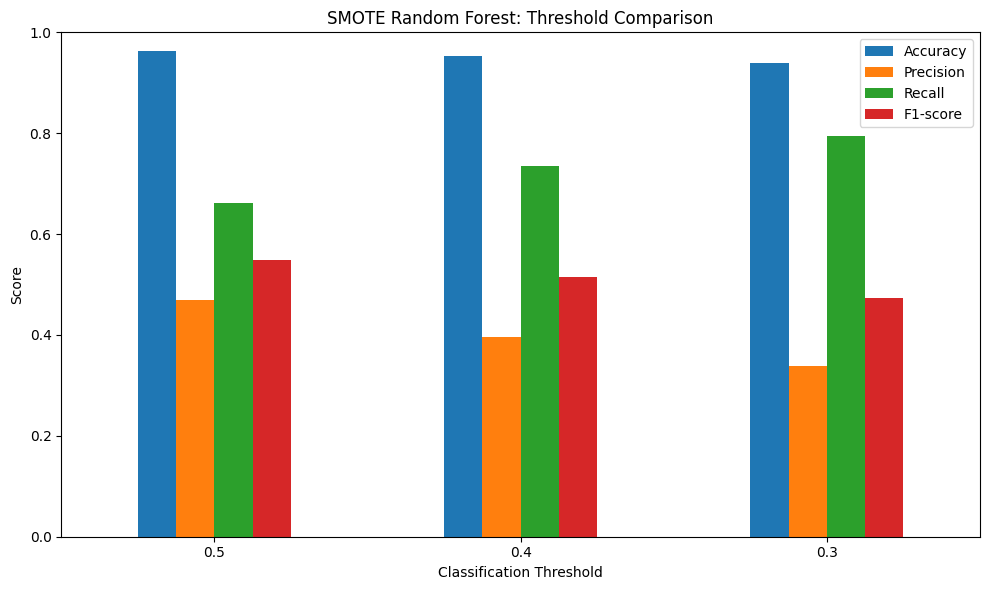

In [56]:

import matplotlib.pyplot as plt

# Metrics to compare
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

# Create the bar chart using the calculated comparison table
threshold_comparison.set_index("Threshold")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SMOTE Random Forest: Threshold Comparison")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


#S15. Final Model Evaluation

##Create the final model comparison table

In [57]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Compare all models
model_predictions = {
    "Original Random Forest": y_pred_rf,
    "Balanced Random Forest": y_pred_rf_balanced,
    "SMOTE Random Forest (0.5)": y_pred_rf_smote,
    "SMOTE Random Forest (0.4)": y_pred_rf_smote_04,
    "SMOTE Random Forest (0.3)": y_pred_rf_smote_03
}

# Calculate performance metrics
final_results = []

for model_name, predictions in model_predictions.items():
    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

# Display comparison table
final_comparison = pd.DataFrame(final_results)

display(
    final_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score
0,Original Random Forest,97.70%,86.67%,38.24%,53.06%
1,Balanced Random Forest,97.65%,86.21%,36.76%,51.55%
2,SMOTE Random Forest (0.5),96.30%,46.88%,66.18%,54.88%
3,SMOTE Random Forest (0.4),95.30%,39.68%,73.53%,51.55%
4,SMOTE Random Forest (0.3),94.00%,33.75%,79.41%,47.37%


## Create the Final Model Comparison Graph

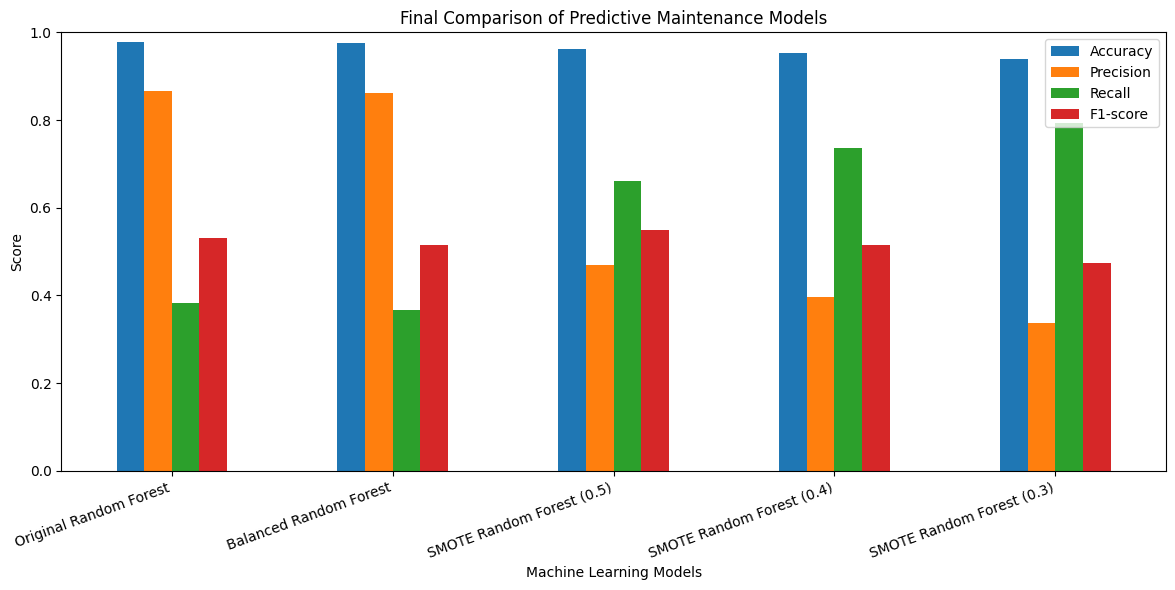

In [58]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

final_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Comparison of Predictive Maintenance Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

## Identify Your Best Model

In [59]:
# Model with the highest recall
best_recall_model = final_comparison.loc[
    final_comparison["Recall"].idxmax()
]

# Model with the highest F1-score
best_f1_model = final_comparison.loc[
    final_comparison["F1-score"].idxmax()
]

print("Best model for detecting failures (highest recall):")
print(best_recall_model)

print("\nBest model by F1-score:")
print(best_f1_model)

Best model for detecting failures (highest recall):
Model        SMOTE Random Forest (0.3)
Accuracy                          0.94
Precision                       0.3375
Recall                        0.794118
F1-score                      0.473684
Name: 4, dtype: object

Best model by F1-score:
Model        SMOTE Random Forest (0.5)
Accuracy                         0.963
Precision                      0.46875
Recall                        0.661765
F1-score                       0.54878
Name: 2, dtype: object


## Model Selection and Performance Analysis

The SMOTE Random Forest model was evaluated using different classification thresholds to study the trade-off between failure detection and prediction reliability.

At a threshold of 0.3, the model achieved a recall of 79.41%, an accuracy of approximately 94.00%, a precision of 33.75%, and an F1-score of 47.37%. This threshold detected a larger proportion of actual failures but produced more false-positive predictions.

At a threshold of 0.5, the model achieved a recall of 66.18%, an accuracy of 96.30%, a precision of 46.88%, and an F1-score of 54.88%. This configuration provided a better balance between precision and recall, as reflected by its higher F1-score.

Therefore, the choice of threshold depends on the practical requirements of predictive maintenance. A lower threshold may be appropriate when missed failures are particularly costly, whereas a higher threshold may be preferable when reducing false alarms is important.

# S16. Conclusion



## Conclusion

In this project, machine learning techniques were used to predict potential machine failures using the AI4I 2020 Predictive Maintenance dataset. Different classification models were evaluated using performance metrics such as accuracy, precision, recall, and F1-score.

To address the class imbalance in the dataset, techniques such as class weighting and the Synthetic Minority Over-sampling Technique (SMOTE) were explored. Different classification thresholds were also tested to investigate their effect on failure detection.

The results showed that the Original Random Forest achieved the highest accuracy of 97.70%, while the SMOTE Random Forest with a threshold of 0.3 achieved the highest recall of 79.41%. The SMOTE Random Forest with a threshold of 0.5 achieved the highest F1-score of 54.88% among the evaluated models. These results demonstrate that accuracy alone is insufficient for evaluating predictive maintenance models.

Recall is particularly important in predictive maintenance because failing to identify an actual machine failure may result in unexpected downtime and increased maintenance costs. However, precision must also be considered to reduce false alarms and unnecessary maintenance interventions.

Overall, this project demonstrates how machine learning can support predictive maintenance by identifying machines that may be at risk of failure. The choice of the final model and classification threshold should depend on the practical balance between failure detection, false alarms, and maintenance requirements.
